<a href="https://colab.research.google.com/github/Aryanshh/CSET343/blob/main/Lab3_1758.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install kagglehub wfdb nltk seaborn scikit-learn statsmodels opencv-python-headless

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 4.3 MB/s eta 0:00:00


In [2]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA

from scipy import stats
from scipy.signal import butter, filtfilt

import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer

import cv2
import wfdb

import warnings
warnings.filterwarnings("ignore")

nltk.download("stopwords")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [3]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA

from scipy import stats
from scipy.signal import butter, filtfilt

import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer

import cv2
import wfdb

import warnings
warnings.filterwarnings("ignore")

nltk.download("stopwords")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [8]:
import pandas as pd
import os

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

df = pd.read_csv(url, names=columns)

print("Dataset downloaded successfully!")
print("Shape:", df.shape)

Dataset downloaded successfully!
Shape: (768, 9)


In [9]:
print("Columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nBasic Statistics:")
display(df.describe())

Columns:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

First 5 rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Basic Statistics:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [10]:
zero_as_missing = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df_clean = df.copy()

for col in zero_as_missing:
    df_clean[col] = df_clean[col].replace(0, np.nan)

print("Missing values after clinical cleaning:")
display(df_clean.isnull().sum())

Missing values after clinical cleaning:


,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [11]:
for col in zero_as_missing:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Remaining missing values:")
print(df_clean.isnull().sum())

Remaining missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


Outcome
0    500
1    268
Name: count, dtype: int64


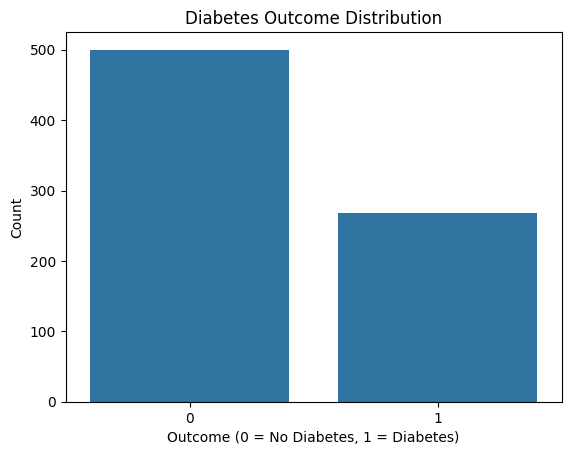

In [12]:
print(df_clean["Outcome"].value_counts())

sns.countplot(data=df_clean, x="Outcome")
plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Count")
plt.show()

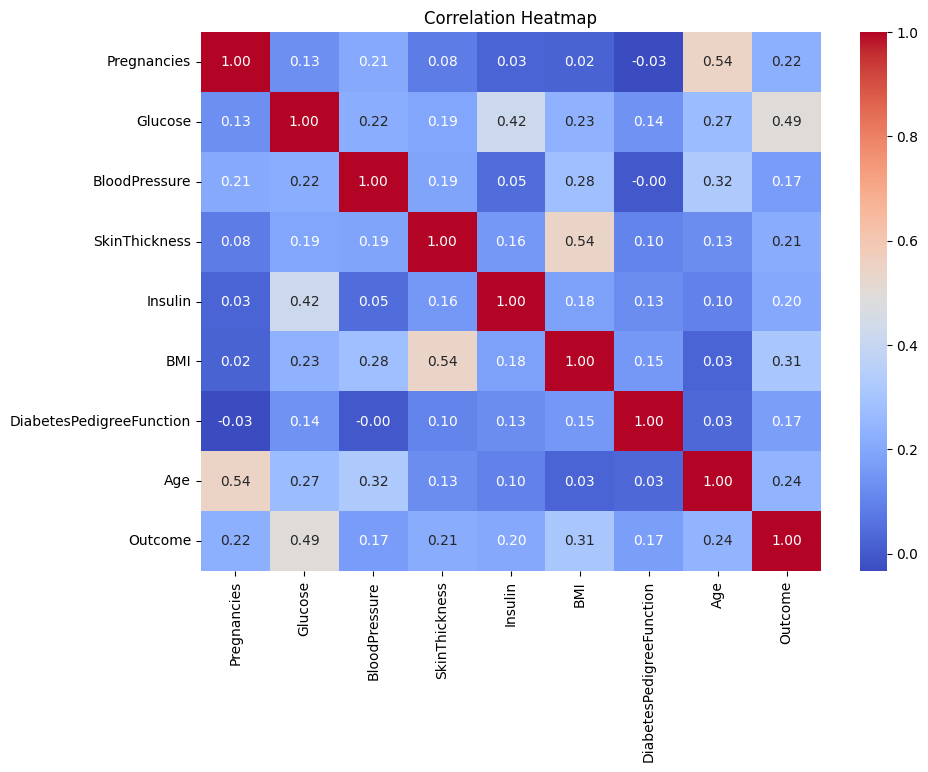

In [13]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df_clean.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

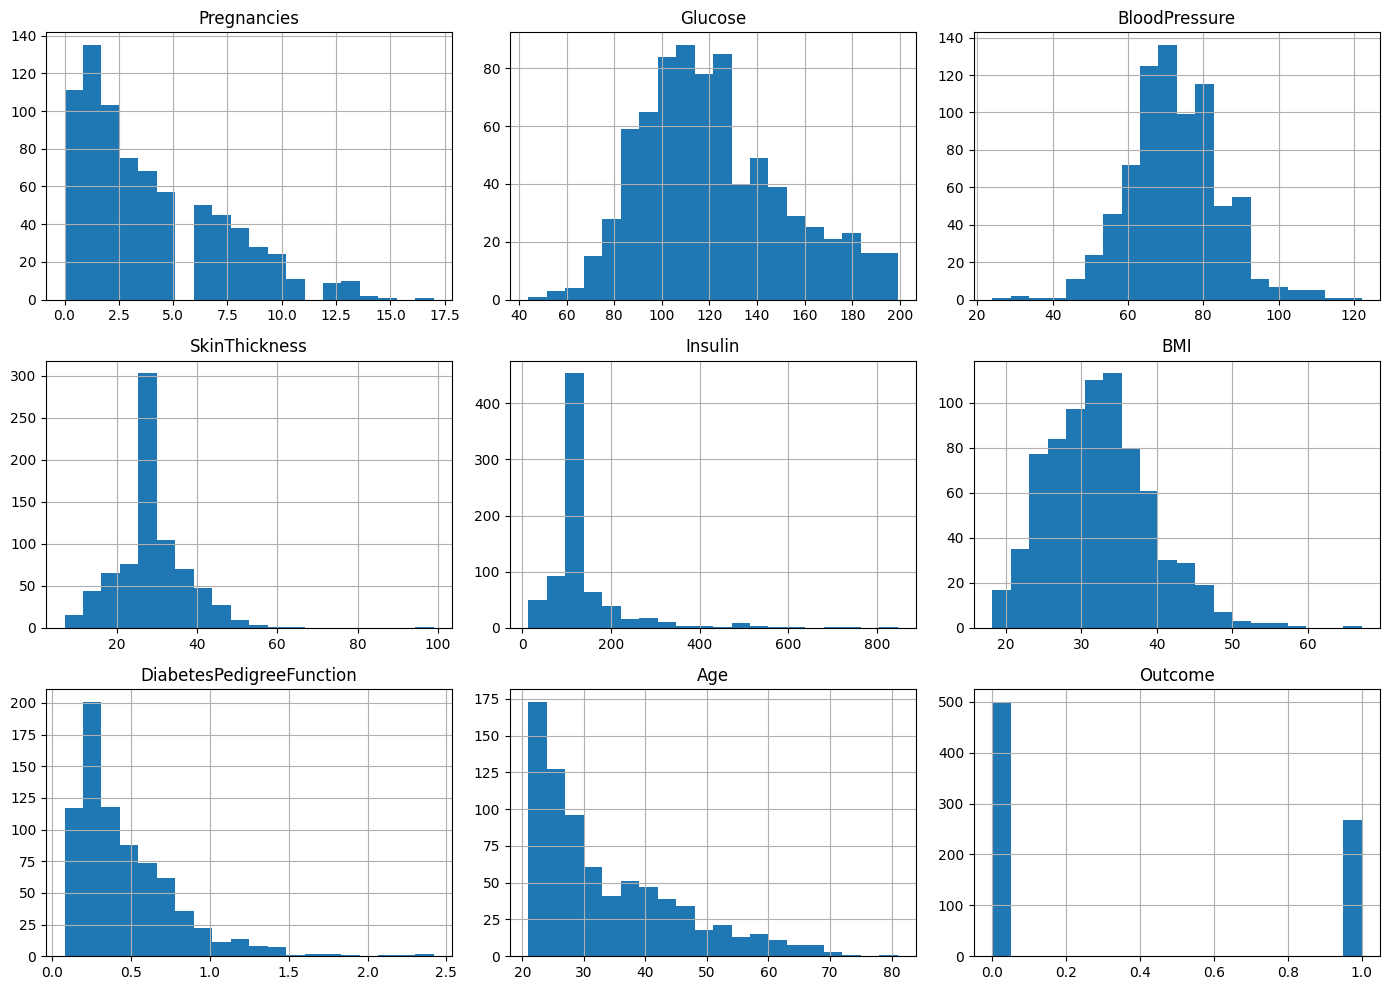

In [14]:
df_clean.hist(
    figsize=(14, 10),
    bins=20
)

plt.tight_layout()
plt.show()

In [16]:
df_clean["BMI_Category"] = pd.cut(
    df_clean["BMI"],
    bins=[0, 18.5, 25, 30, np.inf],
    labels=["Underweight", "Normal", "Overweight", "Obese"]
)

df_clean["Age_Group"] = pd.cut(
    df_clean["Age"],
    bins=[0, 30, 50, np.inf],
    labels=["Young", "Middle", "Older"]
)

display(df_clean.head())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,BMI_Category,Age_Group
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1,Obese,Middle
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0,Overweight,Middle
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1,Normal,Middle
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0,Overweight,Young
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1,Obese,Middle


In [17]:
diabetic = df_clean[df_clean["Outcome"] == 1]["Glucose"]
non_diabetic = df_clean[df_clean["Outcome"] == 0]["Glucose"]

t_stat, p_value = stats.ttest_ind(
    diabetic,
    non_diabetic,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Glucose levels differ significantly.")
else:
    print("Fail to reject H0.")

T-statistic: 14.852653441079662
P-value: 3.5421485614431447e-41
Reject H0: Glucose levels differ significantly.


In [18]:
contingency_table = pd.crosstab(
    df_clean["BMI_Category"],
    df_clean["Outcome"]
)

print(contingency_table)

chi2, p, dof, expected = stats.chi2_contingency(contingency_table)

print("\nChi-square statistic:", chi2)
print("P-value:", p)
print("Degrees of freedom:", dof)

if p < 0.05:
    print("Significant association exists.")
else:
    print("No significant association found.")

Outcome         0    1
BMI_Category          
Underweight     4    0
Normal        101    7
Overweight    136   44
Obese         259  217

Chi-square statistic: 73.13331881767633
P-value: 9.101656268510895e-16
Degrees of freedom: 3
Significant association exists.


In [19]:
groups = [
    group["Glucose"].values
    for _, group in df_clean.groupby(
        "BMI_Category",
        observed=True
    )
]

f_stat, p_value = stats.f_oneway(*groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Significant difference exists between groups.")
else:
    print("No significant difference found.")

F-statistic: 13.254241118590004
P-value: 1.9249439734881206e-08
Significant difference exists between groups.


In [20]:
X = df_clean.drop(
    columns=["Outcome", "BMI_Category", "Age_Group"]
)

y = df_clean["Outcome"]

selector = SelectKBest(
    score_func=f_classif,
    k=5
)

X_selected = selector.fit_transform(X, y)

selected_features = X.columns[selector.get_support()]

print("Selected Features:")
print(selected_features.tolist())

Selected Features:
['Pregnancies', 'Glucose', 'SkinThickness', 'BMI', 'Age']


In [22]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_selected)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (768, 5)


In [23]:
path_text = kagglehub.dataset_download(
    "tboyle10/medicaltranscriptions"
)

print(path_text)
print(os.listdir(path_text))

100%|██████████| 4.85M/4.85M [00:00<00:00, 122MB/s]

Extracting files...
/root/.cache/kagglehub/datasets/tboyle10/medicaltranscriptions/versions/1
['mtsamples.csv']


In [24]:
files = os.listdir(path_text)

csv_files = [
    f for f in files
    if f.endswith(".csv")
]

print(csv_files)

text_df = pd.read_csv(
    os.path.join(path_text, csv_files[0])
)

print("Shape:", text_df.shape)
display(text_df.head())

['mtsamples.csv']
Shape: (4999, 6)


,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."


In [25]:
print(text_df.columns.tolist())

print("\nMissing values:")
print(text_df.isnull().sum())

print("\nDuplicate rows:")
print(text_df.duplicated().sum())

['Unnamed: 0', 'description', 'medical_specialty', 'sample_name', 'transcription', 'keywords']

Missing values:
Unnamed: 0              0
description             0
medical_specialty       0
sample_name             0
transcription          33
keywords             1068
dtype: int64

Duplicate rows:
0


In [26]:
def remove_phi(text):

    if pd.isna(text):
        return ""

    text = str(text)

    # Email addresses
    text = re.sub(
        r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Z|a-z]{2,}\b',
        '[EMAIL]',
        text
    )

    # Phone numbers
    text = re.sub(
        r'\b\d{3}[-.]?\d{3}[-.]?\d{4}\b',
        '[PHONE]',
        text
    )

    # Dates
    text = re.sub(
        r'\b\d{1,2}[/-]\d{1,2}[/-]\d{2,4}\b',
        '[DATE]',
        text
    )

    return text

In [27]:
text_column = "transcription"

text_df["clean_text"] = text_df[text_column].fillna("")

text_df["clean_text"] = text_df["clean_text"].apply(remove_phi)

text_df["clean_text"] = text_df["clean_text"].str.lower()

text_df["clean_text"] = text_df["clean_text"].apply(
    lambda x: re.sub(r'[^a-zA-Z\s]', ' ', x)
)

text_df["clean_text"] = text_df["clean_text"].apply(
    lambda x: re.sub(r'\s+', ' ', x).strip()
)

display(text_df[["clean_text"]].head())

,clean_text
0,subjective this year old white female presents...
1,past medical history he has difficulty climbin...
2,history of present illness i have seen abc tod...
3,d m mode left atrial enlargement with left atr...
4,the left ventricular cavity size and wall thic...


In [28]:
stop_words = set(stopwords.words("english"))

def remove_stopwords(text):
    return " ".join(
        word for word in text.split()
        if word not in stop_words
    )

text_df["processed_text"] = text_df["clean_text"].apply(
    remove_stopwords
)

display(text_df[["processed_text"]].head())

,processed_text
0,subjective year old white female presents comp...
1,past medical history difficulty climbing stair...
2,history present illness seen abc today pleasan...
3,mode left atrial enlargement left atrial diame...
4,left ventricular cavity size wall thickness ap...


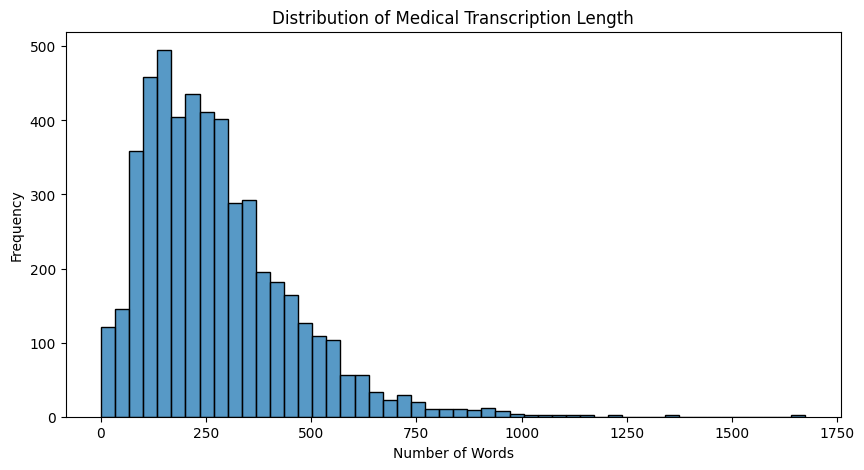

In [29]:
text_df["text_length"] = text_df["processed_text"].apply(
    lambda x: len(x.split())
)

plt.figure(figsize=(10, 5))

sns.histplot(
    text_df["text_length"],
    bins=50
)

plt.title("Distribution of Medical Transcription Length")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

In [30]:
from collections import Counter

words = " ".join(
    text_df["processed_text"]
).split()

word_counts = Counter(words)

print("Most common medical words:")
print(word_counts.most_common(20))

Most common medical words:
[('patient', 24208), ('right', 11587), ('left', 11258), ('history', 9509), ('normal', 7526), ('procedure', 7463), ('placed', 7028), ('well', 6611), ('pain', 5976), ('mg', 4375), ('x', 4357), ('noted', 4348), ('also', 4337), ('time', 4287), ('c', 4132), ('using', 4123), ('blood', 3956), ('performed', 3953), ('skin', 3798), ('without', 3732)]


In [31]:
vectorizer = TfidfVectorizer(
    max_features=1000,
    min_df=2
)

X_text = vectorizer.fit_transform(
    text_df["processed_text"]
)

print("TF-IDF shape:", X_text.shape)

TF-IDF shape: (4999, 1000)


In [32]:
text_features = X_text.toarray()

print("Model-ready text tensor shape:")
print(text_features.shape)

Model-ready text tensor shape:
(4999, 1000)


In [33]:
path_image = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

print(path_image)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
/kaggle/input/chest-xray-pneumonia


In [34]:
for root, dirs, files in os.walk(path_image):
    if files:
        print(root, "->", len(files), "files")

/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray -> 1 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val -> 1 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val/PNEUMONIA -> 9 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val/NORMAL -> 9 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/test -> 1 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/test/PNEUMONIA -> 390 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/test/NORMAL -> 234 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/train -> 1 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/train/PNEUMONIA -> 3876 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/train/NORMAL -> 1342 files
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX -> 1 files
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray -> 3 files
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/val -

In [35]:
image_paths = []

for root, dirs, files in os.walk(path_image):
    for file in files:
        if file.lower().endswith(
            (".jpeg", ".jpg", ".png")
        ):
            image_paths.append(
                os.path.join(root, file)
            )

print("Total images:", len(image_paths))

Total images: 17568


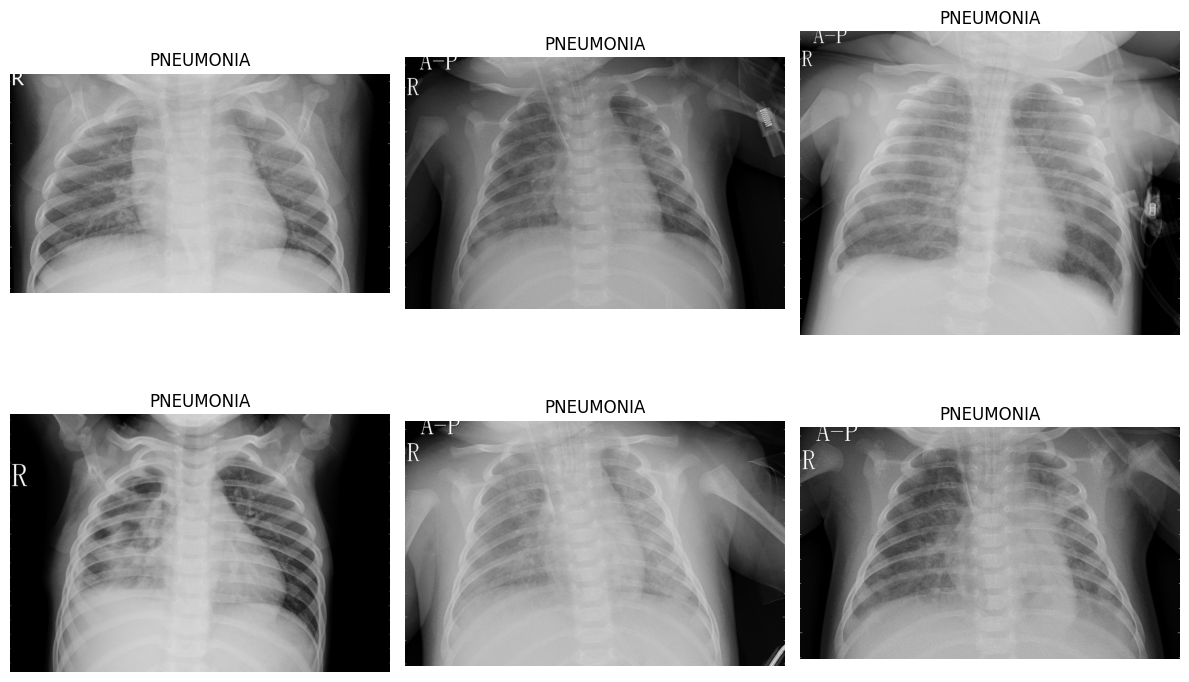

In [36]:
plt.figure(figsize=(12, 8))

for i, img_path in enumerate(image_paths[:6]):

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(os.path.basename(os.path.dirname(img_path)))

plt.tight_layout()
plt.show()

In [37]:
IMG_SIZE = 224

def preprocess_image(path):

    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    # Resize
    img = cv2.resize(
        img,
        (IMG_SIZE, IMG_SIZE)
    )

    # Normalize to [0,1]
    img = img.astype(np.float32) / 255.0

    # Add channel dimension
    img = np.expand_dims(img, axis=-1)

    return img

In [38]:
X_images = []
y_images = []

for img_path in image_paths:

    try:
        img = preprocess_image(img_path)

        label = os.path.basename(
            os.path.dirname(img_path)
        )

        X_images.append(img)
        y_images.append(label)

    except Exception as e:
        print("Error:", img_path, e)

X_images = np.array(X_images)

print("Image tensor:", X_images.shape)
print("Labels:", len(y_images))

Streaming output truncated to the last 5000 lines.
Error: /kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/train/PNEUMONIA/._person1102_virus_1822.jpeg OpenCV(4.14.0) /io/opencv/modules/imgproc/src/resize.cpp:4014: error: (-215:Assertion failed) !ssize.empty() in function 'resize'

Error: /kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/train/PNEUMONIA/._person608_bacteria_2472.jpeg OpenCV(4.14.0) /io/opencv/modules/imgproc/src/resize.cpp:4014: error: (-215:Assertion failed) !ssize.empty() in function 'resize'

Error: /kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/train/PNEUMONIA/._person408_bacteria_1823.jpeg OpenCV(4.14.0) /io/opencv/modules/imgproc/src/resize.cpp:4014: error: (-215:Assertion failed) !ssize.empty() in function 'resize'

Error: /kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/train/PNEUMONIA/._person462_virus_951.jpeg OpenCV(4.14.0) /io/opencv/modules/imgproc/src/resize.cpp:4014: error: (-215:Assert

In [39]:
label_encoder = LabelEncoder()

y_images_encoded = label_encoder.fit_transform(
    y_images
)

print(
    dict(
        zip(
            label_encoder.classes_,
            np.unique(y_images_encoded)
        )
    )
)

{np.str_('NORMAL'): np.int64(0), np.str_('PNEUMONIA'): np.int64(1)}


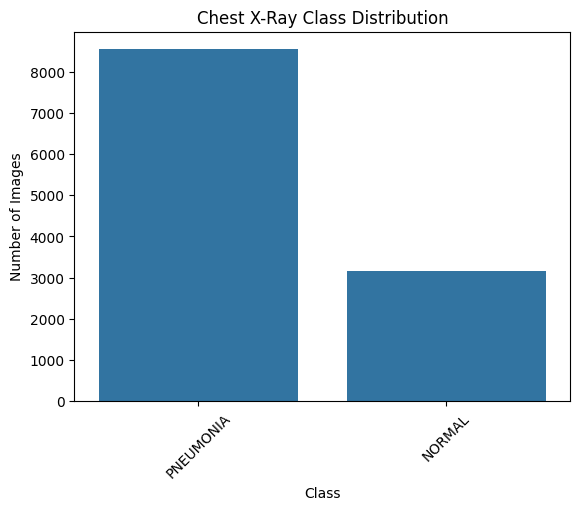

In [40]:
sns.countplot(x=y_images)

plt.title("Chest X-Ray Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.show()

In [41]:
def augment_image(img):

    # Horizontal flip
    flipped = np.fliplr(img)

    # Small brightness modification
    bright = np.clip(
        img * 1.15,
        0,
        1
    )

    return flipped, bright

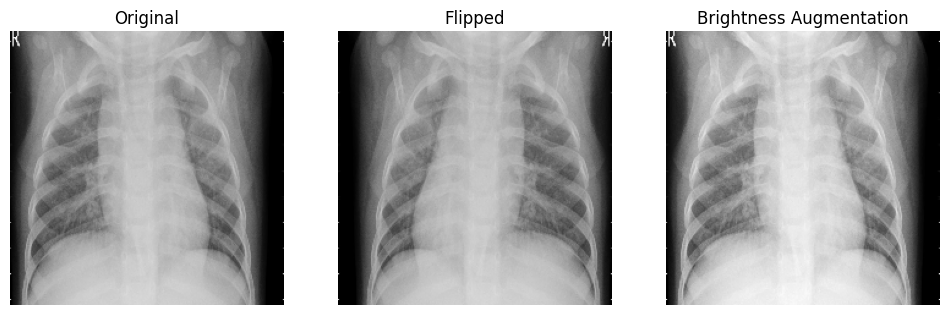

In [42]:
original = X_images[0]

flipped, bright = augment_image(original)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original.squeeze(), cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(flipped.squeeze(), cmap="gray")
plt.title("Flipped")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(bright.squeeze(), cmap="gray")
plt.title("Brightness Augmentation")
plt.axis("off")

plt.show()

In [43]:
import wfdb

record = wfdb.rdrecord(
    "100",
    pn_dir="mitdb"
)

print("Signal shape:", record.p_signal.shape)
print("Sampling frequency:", record.fs)
print("Signal names:", record.sig_name)

Signal shape: (650000, 2)
Sampling frequency: 360
Signal names: ['MLII', 'V5']


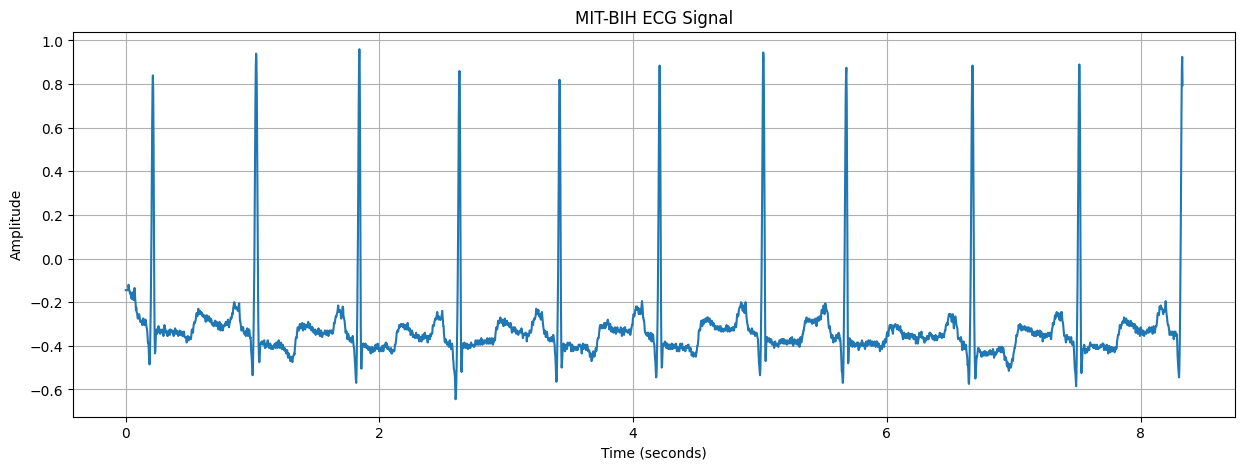

In [44]:
signal = record.p_signal[:, 0]

time = np.arange(len(signal)) / record.fs

plt.figure(figsize=(15, 5))

plt.plot(
    time[:3000],
    signal[:3000]
)

plt.title("MIT-BIH ECG Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()

plt.show()

In [45]:
print("Sampling frequency:", record.fs)
print("Number of samples:", len(signal))
print("Duration:", len(signal) / record.fs, "seconds")

Sampling frequency: 360
Number of samples: 650000
Duration: 1805.5555555555557 seconds


In [46]:
def bandpass_filter(
    signal,
    lowcut=0.5,
    highcut=40,
    fs=360,
    order=4
):

    nyquist = 0.5 * fs

    low = lowcut / nyquist
    high = highcut / nyquist

    b, a = butter(
        order,
        [low, high],
        btype="band"
    )

    filtered = filtfilt(
        b,
        a,
        signal
    )

    return filtered

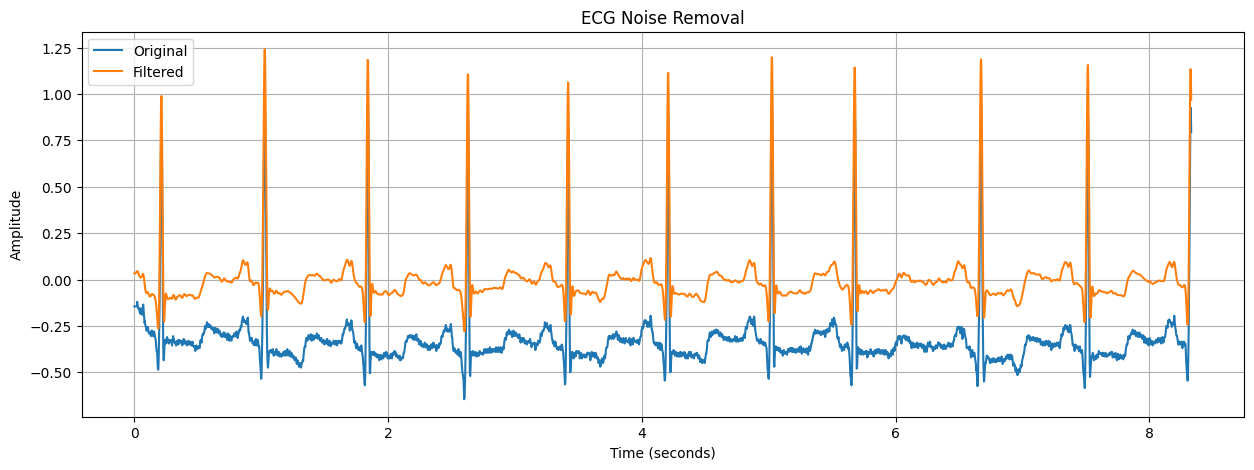

In [47]:
filtered_signal = bandpass_filter(
    signal,
    fs=record.fs
)

plt.figure(figsize=(15, 5))

plt.plot(
    time[:3000],
    signal[:3000],
    label="Original"
)

plt.plot(
    time[:3000],
    filtered_signal[:3000],
    label="Filtered"
)

plt.title("ECG Noise Removal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.legend()
plt.grid()

plt.show()

In [48]:
WINDOW_SIZE = 360  # 1 second at 360 Hz

windows = []

for i in range(
    0,
    len(filtered_signal) - WINDOW_SIZE,
    WINDOW_SIZE
):

    window = filtered_signal[
        i:i + WINDOW_SIZE
    ]

    windows.append(window)

X_signal = np.array(windows)

print("Signal windows shape:")
print(X_signal.shape)

Signal windows shape:
(1805, 360)


In [49]:
signal_mean = X_signal.mean(axis=1, keepdims=True)
signal_std = X_signal.std(axis=1, keepdims=True)

X_signal_normalized = (
    X_signal - signal_mean
) / (
    signal_std + 1e-8
)

print(
    "Normalized signal shape:",
    X_signal_normalized.shape
)

Normalized signal shape: (1805, 360)


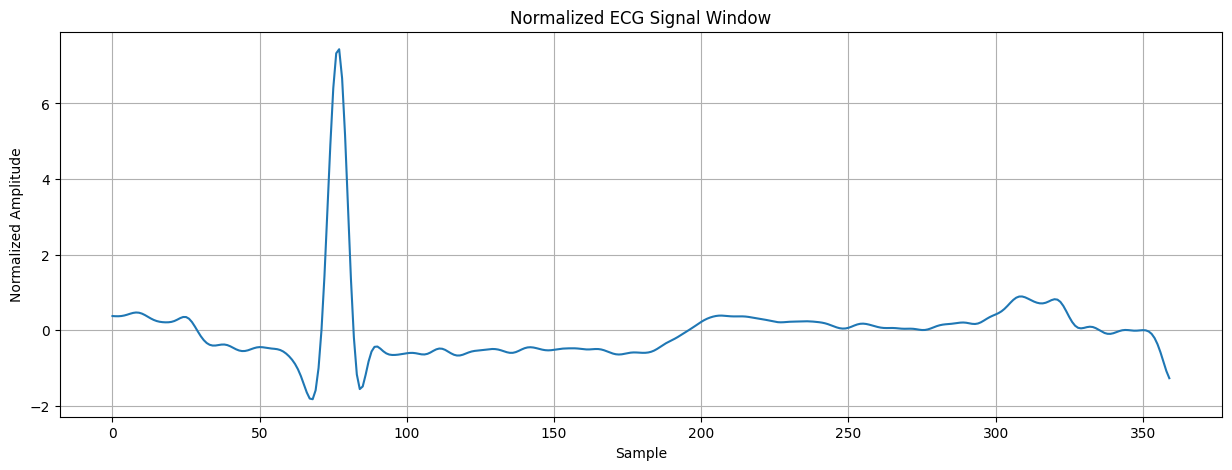

In [50]:
plt.figure(figsize=(15, 5))

plt.plot(
    X_signal_normalized[0]
)

plt.title("Normalized ECG Signal Window")
plt.xlabel("Sample")
plt.ylabel("Normalized Amplitude")
plt.grid()

plt.show()

In [51]:
print("=" * 60)
print("AI IN HEALTHCARE — DATA PREPROCESSING SUMMARY")
print("=" * 60)

print("\n1. TABULAR DATA")
print("Original shape:", df.shape)
print("Processed shape:", X_scaled.shape)

print("\n2. TEXT DATA")
print("Original records:", len(text_df))
print("TF-IDF features:", X_text.shape)

print("\n3. IMAGE DATA")
print("Images:", X_images.shape)
print("Labels:", len(y_images_encoded))

print("\n4. SIGNAL DATA")
print("Original samples:", len(signal))
print("Signal windows:", X_signal_normalized.shape)

print("\n" + "=" * 60)
print("Preprocessing completed successfully.")
print("=" * 60)

AI IN HEALTHCARE — DATA PREPROCESSING SUMMARY

1. TABULAR DATA
Original shape: (768, 9)
Processed shape: (768, 5)

2. TEXT DATA
Original records: 4999
TF-IDF features: (4999, 1000)

3. IMAGE DATA
Images: (11712, 224, 224, 1)
Labels: 11712

4. SIGNAL DATA
Original samples: 650000
Signal windows: (1805, 360)

Preprocessing completed successfully.


In [52]:
print("""
OBSERVATIONS:

1. Tabular:
   - Healthcare datasets can encode missing values as clinically invalid values.
   - Zero values were treated as missing for relevant medical attributes.
   - Scaling and feature selection were performed.
   - Hypothesis testing, Chi-square testing and ANOVA were performed.

2. Text:
   - Medical text requires privacy-aware preprocessing.
   - PHI-like information such as emails, phone numbers and dates was removed.
   - Text was cleaned and transformed using TF-IDF.

3. Image:
   - X-ray images were converted to grayscale.
   - Images were resized to 224 x 224.
   - Pixel values were normalized to [0,1].
   - Basic augmentation was demonstrated.

4. Signal:
   - ECG signals contain noise and baseline variations.
   - A band-pass filter was applied.
   - ECG was divided into fixed-size windows.
   - Signal windows were normalized.

Healthcare data requires additional preprocessing because
clinical plausibility, patient privacy, class imbalance,
noise and missing-value representation can directly affect
the reliability and safety of AI models.
""")


OBSERVATIONS:

1. Tabular:
   - Healthcare datasets can encode missing values as clinically invalid values.
   - Zero values were treated as missing for relevant medical attributes.
   - Scaling and feature selection were performed.
   - Hypothesis testing, Chi-square testing and ANOVA were performed.

2. Text:
   - Medical text requires privacy-aware preprocessing.
   - PHI-like information such as emails, phone numbers and dates was removed.
   - Text was cleaned and transformed using TF-IDF.

3. Image:
   - X-ray images were converted to grayscale.
   - Images were resized to 224 x 224.
   - Pixel values were normalized to [0,1].
   - Basic augmentation was demonstrated.

4. Signal:
   - ECG signals contain noise and baseline variations.
   - A band-pass filter was applied.
   - ECG was divided into fixed-size windows.
   - Signal windows were normalized.

Healthcare data requires additional preprocessing because
clinical plausibility, patient privacy, class imbalance,
noise and mi